# Customer Shopping Behavior Analysis

**Business problem:** A retailer wants to understand how its customers shop: what they buy, how much they spend, and how discounts, subscriptions and shipping choices relate to spending and loyalty. The goal is to turn this into recommendations the business can act on.

**Workflow:** Python (pandas) for cleaning and preparation → PostgreSQL for business queries → statistical tests → Tableau for the interactive dashboard.

## 1. Load the data

In [10]:
import pandas as pd

df = pd.read_csv('../data/customer_shopping_behavior.csv')



## 2. Explore the dataset

A first look at the rows, column types and summary statistics.

In [11]:
# Display the first few rows of the dataset
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [13]:
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


### Key observations
- **3,900 purchases** across **18 columns**: customer demographics, product details, purchase amount, review rating, and shopping behavior.
- Purchase amounts range from **\$20 to \$100**, with an average of about **\$59.76**.
- Only one column has missing values; checking below.

## 3. Clean the data

In [14]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

### Handle missing review ratings
`review_rating` has **37 missing values** (about 1% of rows). Instead of dropping those purchases, I filled each one with the **median rating of its product category**. Ratings vary by category, so a category-level median is more accurate than one overall average.

In [15]:
df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(lambda x: x.fillna(x.median()))

In [16]:
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

### Standardize column names
Converted all column names to lowercase snake_case (e.g., `Purchase Amount (USD)` → `purchase_amount`) so they're easy to query in SQL without quotes.

In [17]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '_')
df = df.rename(columns={'purchase_amount_(usd)':'purchase_amount'})

In [18]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

## 4. Feature engineering

### Age groups
Split customers into four equal-sized age groups using quartiles: **Young Adult, Adult, Middle-aged, Senior**. This makes it easy to compare spending and behavior across life stages.

In [19]:
# create a new column age_group

labels = ['Young Adult', 'Adult', 'Middle-aged', 'Senior']
df['age_group'] = pd.qcut(df['age'], q=4, labels=labels)

In [20]:
# Show the age and newly created age_group columns
df[['age', 'age_group']].head(10)

,age,age_group
0,55,Middle-aged
1,19,Young Adult
2,50,Middle-aged
3,21,Young Adult
4,45,Middle-aged
5,46,Middle-aged
6,63,Senior
7,27,Young Adult
8,26,Young Adult
9,57,Middle-aged


### Purchase frequency in days
Converted the text values in `frequency_of_purchases` (e.g., "Weekly", "Quarterly") into a number of days, so purchase frequency can be compared and averaged. "Fortnightly" and "Bi-Weekly" both map to 14 days, and "Quarterly" and "Every 3 Months" both map to 90.

In [21]:
# create column purchase_frequency_days

frequency_mapping = {
    'Fortnightly': 14,
    'Weekly': 7,
    'Monthly': 30,
    'Quarterly': 90,
    'Bi-Weekly': 14,
    'Annually': 365,
    'Every 3 Months': 90
}

df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)

In [22]:
df[['purchase_frequency_days', 'frequency_of_purchases']].head(10)

,purchase_frequency_days,frequency_of_purchases
0,14,Fortnightly
1,14,Fortnightly
2,7,Weekly
3,7,Weekly
4,365,Annually
5,7,Weekly
6,90,Quarterly
7,7,Weekly
8,365,Annually
9,90,Quarterly


### Check for redundant columns
`discount_applied` and `promo_code_used` look identical. Checking whether they match on every row:

In [23]:
df[['discount_applied', 'promo_code_used']].head(10)

,discount_applied,promo_code_used
0,Yes,Yes
1,Yes,Yes
2,Yes,Yes
3,Yes,Yes
4,Yes,Yes
5,Yes,Yes
6,Yes,Yes
7,Yes,Yes
8,Yes,Yes
9,Yes,Yes


In [24]:
(df['discount_applied'] == df['promo_code_used']).all()

np.True_

They match on **all 3,900 rows**, so `promo_code_used` adds no information. Dropping it to avoid double-counting in the analysis.

In [25]:
df = df.drop('promo_code_used', axis=1)

In [26]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days'],
      dtype='object')

## 5. Load the clean data into PostgreSQL

Installing the libraries Python needs to connect to PostgreSQL.

In [27]:
pip install psycopg2-binary sqlalchemy

Note: you may need to restart the kernel to use updated packages.


Connecting to a local PostgreSQL database (`customer_behavior`) and writing the cleaned DataFrame to a table called `customer`. From here, the business questions are answered in SQL.

In [30]:
from sqlalchemy import create_engine

# Step 1: Connect to PostgreSQL
# Homebrew Postgres: user = your Mac username, no password
username = "afeefshaikh"        # your Mac username (check with `whoami` in Terminal)
host = "localhost"
port = "5432"
database = "customer_behavior"  # the database we created with createdb

engine = create_engine(f"postgresql+psycopg2://{username}@{host}:{port}/{database}")

# Step 2: Load DataFrame into PostgreSQL
table_name = "customer"
df.to_sql(table_name, engine, if_exists="replace", index=False)

print(f"Data successfully loaded into table '{table_name}' in database '{database}'.")

Data successfully loaded into table 'customer' in database 'customer_behavior'.


## 6. Hypothesis testing: do subscribers actually spend more?

The SQL analysis (Q5) compared average spend for subscribers and non-subscribers, but a difference in averages can just be noise. Here I test it properly.

- **H₀:** Subscribers and non-subscribers spend the same per purchase.
- **H₁:** Their spend per purchase is different.
- Significance level: α = 0.05

The data is pulled straight from PostgreSQL, so this analysis reads from the same database as the SQL queries.

                     count   mean  median    std
subscription_status                             
No                    2847  59.87    60.0  23.78
Yes                   1053  59.49    60.0  23.45


/var/folders/q0/3s_mjsr548n2n9fr2zymmzyc0000gn/T/ipykernel_18448/1740278625.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([non, subs], labels=['Non-subscribers', 'Subscribers'])


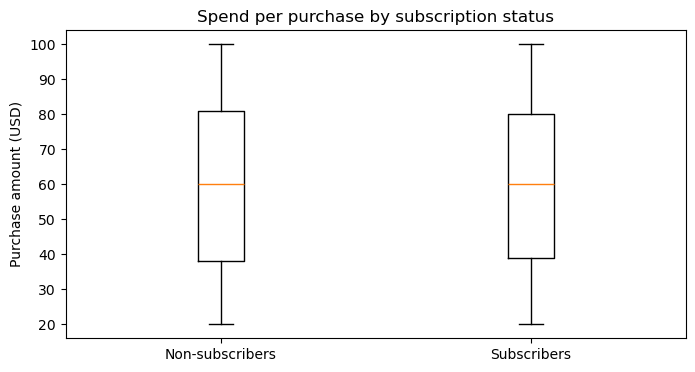

In [32]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

data = pd.read_sql("SELECT subscription_status, purchase_amount, previous_purchases FROM customer", engine)

subs = data.loc[data['subscription_status'] == 'Yes', 'purchase_amount']
non  = data.loc[data['subscription_status'] == 'No',  'purchase_amount']

print(data.groupby('subscription_status')['purchase_amount']
          .agg(['count', 'mean', 'median', 'std']).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([non, subs], labels=['Non-subscribers', 'Subscribers'])
ax.set_ylabel('Purchase amount (USD)')
ax.set_title('Spend per purchase by subscription status')
plt.show()

### Running the tests
- **Welch's t-test** compares the two means without assuming equal variances.
- **Mann-Whitney U** is a check that doesn't assume normal data. Purchase amounts are spread fairly evenly from \$20 to \$100, not bell-shaped, so it's worth confirming with both.
- **Effect size (Cohen's d)** and a **95% confidence interval** show *how big* the difference is, not just whether it exists.

In [33]:
t_stat, p_t = stats.ttest_ind(subs, non, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(subs, non, alternative='two-sided')

diff = subs.mean() - non.mean()
v1, v2, n1, n2 = subs.var(ddof=1), non.var(ddof=1), len(subs), len(non)
se = np.sqrt(v1/n1 + v2/n2)
dof = se**4 / ((v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1))
ci_low, ci_high = diff - stats.t.ppf(0.975, dof)*se, diff + stats.t.ppf(0.975, dof)*se
cohens_d = diff / np.sqrt((v1 + v2) / 2)

print(f"Difference in mean spend (subs - non): ${diff:.2f}")
print(f"95% CI: (${ci_low:.2f}, ${ci_high:.2f})")
print(f"Welch t-test p-value: {p_t:.4f}")
print(f"Mann-Whitney p-value: {p_u:.4f}")
print(f"Cohen's d: {cohens_d:.3f}")

Difference in mean spend (subs - non): $-0.37
95% CI: ($-2.04, $1.29)
Welch t-test p-value: 0.6603
Mann-Whitney p-value: 0.6657
Cohen's d: -0.016


## 7. Are repeat buyers more likely to subscribe?

SQL Q9 counted subscribers among repeat buyers. A **chi-square test of independence** checks whether repeat buyers (more than 5 previous purchases) subscribe at a different *rate* than other customers.

In [34]:
data['repeat_buyer'] = np.where(data['previous_purchases'] > 5, 'Repeat (>5)', 'Not repeat (≤5)')
table = pd.crosstab(data['repeat_buyer'], data['subscription_status'])
print(table, "\n")
print((pd.crosstab(data['repeat_buyer'], data['subscription_status'], normalize='index') * 100).round(1), "\n")

chi2, p_chi, dof_chi, _ = stats.chi2_contingency(table)
print(f"Chi-square = {chi2:.2f}, p-value = {p_chi:.4f}")

subscription_status    No  Yes
repeat_buyer                  
Not repeat (≤5)       329   95
Repeat (>5)          2518  958 

subscription_status    No   Yes
repeat_buyer                   
Not repeat (≤5)      77.6  22.4
Repeat (>5)          72.4  27.6 

Chi-square = 4.84, p-value = 0.0279


## 8. Findings and recommendations

**1. Subscribers do not spend more per purchase.**
Subscribers spent **\$59.49** per purchase on average vs. **\$59.87** for non-subscribers, a difference of **−\$0.37** (95% CI: −\$2.04 to \$1.29). The difference is **not statistically significant** (Welch's t-test p = 0.66, Mann-Whitney p = 0.67), and the effect size is negligible (Cohen's d = −0.016). The confidence interval tells us that even in the best case, subscribers spend at most about \$1.29 more per purchase. The two groups have practically identical spending.

**2. Repeat buyers are more likely to subscribe.**
**27.6%** of repeat buyers (more than 5 previous purchases) are subscribers, compared with **22.4%** of other customers, a gap of 5.2 percentage points. This difference is **statistically significant** (χ² = 4.84, p = 0.028). This shows an association, not cause and effect: the data can't tell us whether subscribing makes people buy more often or whether frequent buyers choose to subscribe.

**Recommendations**
- **Judge the subscription program on loyalty, not basket size.** It isn't linked to higher spend per purchase, so promoting it as a way to raise order value won't work. Its value, if any, is in keeping customers coming back.
- **Target subscription offers at customers with more than 5 purchases.** They already subscribe at a higher rate, so they're the most receptive audience for the program.
- **Next step:** track purchase frequency and retention before and after customers subscribe. That would show whether subscriptions *cause* more repeat buying.

## 9. Export the clean data for Tableau

Tableau Public can't connect to a local PostgreSQL database, so the cleaned table is exported to CSV with a `repeat_buyer` flag for the dashboard.

In [ ]:
out = pd.read_sql("SELECT * FROM customer", engine)
out["repeat_buyer"] = np.where(out["previous_purchases"] > 5, "Repeat (>5)", "Not repeat (≤5)")
out.to_csv("../data/customer_clean.csv", index=False)
print(out.shape)